# Issue #11 · synthetic degradation → restoration → real YOLO26n robustness

This is a **calibration-only exploratory screen**, not a final-test result, a natural
real-world robustness claim, or model training. The frozen four roles and v1/v2
policies/notebooks/reports are unchanged. Every perturbation inherits source ID,
group, dimensions and native YOLO labels. Primary training treatments remain Raw/Adaptive.

We compare each restoration with **corrupted Raw under the identical condition**,
using the same pinned pretrained checkpoint and native six-class metric adapter.
Clean Raw is reported separately as a reference, not blended with synthetic AP.
A negative/null result or **no v3 deployment** is a legitimate outcome.

Research sources: [Hendrycks & Dietterich, ICLR 2019](https://arxiv.org/abs/1903.12261)
provides a useful corruption taxonomy, not BDD-specific severities;
[Foi et al., 2008](https://webpages.tuni.fi/foi/papers/Foi-PoissonianGaussianClippedRaw-2007-IEEE_TIP.pdf)
motivates signal-dependent shot + read noise in sensor raw data. We only have processed
BDD JPEGs: inverse gamma 2.2 is an approximation, without sensor/demosaic calibration.
[OpenCV denoising](https://docs.opencv.org/4.x/d5/d69/tutorial_py_non_local_means.html)
and [filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html) describe
available NLM/bilateral tradeoffs; neither implies improved detector AP.

In [1]:
import gzip
import json
import platform
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from IPython.utils.capture import capture_output
from matplotlib.patches import Rectangle
from ultralytics import YOLO

from vehicle_detection.adaptive import validate_policy
from vehicle_detection.baseline import COCO_TO_VEHICLE, PRETRAINED_SHA256, verify_coco_names
from vehicle_detection.common import digest, file_hash, read_image, read_json, write_json
from vehicle_detection.data import CLASSES, convert_labels, scan_bdd
from vehicle_detection.protocol import summarize, validate_protocol
from vehicle_detection.stress import (
    CORRUPTIONS,
    OPERATORS,
    SCREEN,
    converter_records,
    export_stress,
    freeze,
    select_calibration,
)
from vehicle_detection.stress_eval import (
    SETTINGS,
    evaluate_calibration,
    load_stats,
    native_ap,
    paired_interval,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_ROOT = ROOT / "data/bdd100k"
RUN_ROOT, REPORT_ROOT = ROOT / "runs/issue11-v1", ROOT / "docs/issue11-v1"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
cv2.setNumThreads(1)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
protocol = validate_protocol(read_json(ROOT / "runs/issue5-v1/protocol.json"))
v2 = validate_policy(read_json(ROOT / "docs/issue6-v2/policy.json"), protocol)
CHECKPOINT = ROOT / "weights/yolo26n.pt"
assert torch.cuda.is_available()
assert file_hash(CHECKPOINT) == PRETRAINED_SHA256
PILOT_IMAGES, SEED, ATTEMPTS, BOOTSTRAPS = 256, 2026, 64, 100
print("CUDA:", torch.cuda.get_device_name(0))
print("Frozen checkpoint:", PRETRAINED_SHA256)
print("Protocol:", protocol["manifest_id"], "v2 baseline:", v2["policy_id"])
display(pd.Series(SETTINGS, name="Fixed native inference/metric settings"))

CUDA: NVIDIA GeForce RTX 5060 Ti
Frozen checkpoint: 9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef
Protocol: 680090b8eef098fbe10c77e632aacbfd3d6854d8489d7518e20f062e032b6e44 v2 baseline: 1ac3fb9bb94b132f70d3e168b5ef15a54b616444e535b9a3bb265682a6fce0ef


imgsz              640
batch               32
device               0
conf             0.001
iou                0.7
max_det            300
quantize            32
nms              False
agnostic_nms     False
rect              True
augment          False
seed              2026
deterministic     True
workers              0
plots             True
verbose          False
Name: Fixed native inference/metric settings, dtype: object

## Freeze the pilot and bounded experimental matrix before detector results

Choose a whole-group, naturally distributed pilot from the **6,985 calibration**
images using the minimum multi-label/condition drift over 64 seeded permutations.
This finite search is not perfect stratification. Images/groups never move roles.
Rare or absent classes remain unsupported; repeated synthetic copies add no new support.

The predeclared budget is **45 paired datasets**, not a full factorial: clean +
18 corrupted Raw inputs; 12 independent candidate screens at moderate severity;
eight clean-input safety controls; six moderate-condition frozen-v2 controls.
Each candidate is tested independently of routing. A winning screen would require
recovery CI lower bound >0, at least 0.005 mAP recovery, clean loss ≤0.01 mAP and
CPU restore p95 ≤25 ms. Such a result is only a shortlist, **not permission to deploy**:
a v3 router also requires independent calibration-group confirmation and evidence
that pixel-only routing identifies its intended condition without harmful false positives.
This screen has no independent confirmation population, so it cannot release v3.

Why these families: BDD includes night/day, variable weather and moving-road imagery;
exposure, blur, noise and veiling contrast are relevant hypotheses to test. Severity
ranges below are controlled approximations in native pixels, not estimates of actual
BDD camera physics. Severe noise/saturation/blur can make original boxes visually
ambiguous; AP then measures visible-information loss as well as detector weakness.
Rain streaks/glare and explicit JPEG artifacts are excluded from this first screen:
we lack scene/depth/optics justification, and a common JPEG95 roundtrip is already controlled.
No learned deblurring/dehazing dependency or extra training branches are introduced.

Pilot: 256 images; 158 groups
Frozen datasets: 45 study: a7e6b2586bd26454a6fdcb651087f7ed52a59ecee0c0efeebdb765427e47f22c


,images,negative,presence:car,presence:truck,presence:bus,presence:train,presence:motorcycle,presence:bicycle
calibration,6985.0,46.0,6908.0,1918.0,936.0,13.0,239.0,425.0
pilot,256.0,1.0,254.0,75.0,40.0,1.0,10.0,12.0


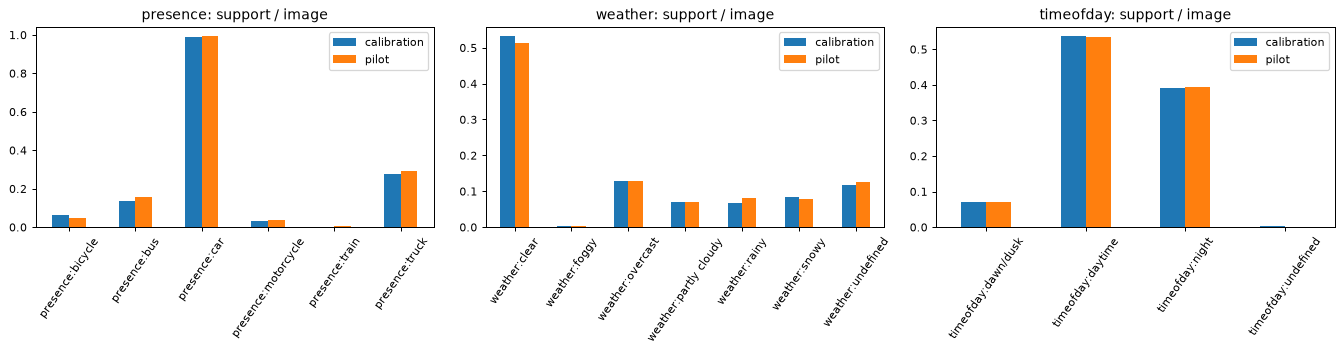

{'shot_read': [{'photons': 800, 'read_sigma': 0.003},
  {'photons': 200, 'read_sigma': 0.008},
  {'photons': 50, 'read_sigma': 0.02}],
 'motion': [{'size': 5}, {'size': 11}, {'size': 21}],
 'defocus': [{'radius': 1}, {'radius': 2}, {'radius': 4}],
 'underexposure': [{'factor': 0.7}, {'factor': 0.45}, {'factor': 0.25}],
 'overexposure': [{'factor': 1.3}, {'factor': 1.7}, {'factor': 2.3}],
 'veil': [{'alpha': 0.1}, {'alpha': 0.25}, {'alpha': 0.4}]}

{'skip': {},
 'gamma': {'gamma': 0.7},
 'darken': {'gamma': 1.3},
 'clahe': {'clip_limit': 1.5, 'grid_size': 8},
 'nlmeans': {'strength': 5.0},
 'bilateral': {'d': 5, 'sigmaColor': 25.0, 'sigmaSpace': 3.0},
 'unsharp': {'amount': 0.4, 'sigma': 1.0},
 'percentile': {'low': 1.0, 'high': 99.0},
 'adaptive_v2': {}}

In [2]:
pilot = select_calibration(protocol, image_count=PILOT_IMAGES, seed=SEED, attempts=ATTEMPTS)
freeze(RUN_ROOT / "pilot.json", pilot)
conditions = [("clean", 0, "skip")]
conditions += [(family, severity, "skip") for family in CORRUPTIONS for severity in [1, 2, 3]]
conditions += [(family, 2, op) for family, ops in SCREEN.items() for op in ops]
clean_ops = sorted({op for ops in SCREEN.values() for op in ops} | {"adaptive_v2"})
conditions += [("clean", 0, op) for op in clean_ops]
conditions += [(family, 2, "adaptive_v2") for family in CORRUPTIONS]
config = {
    "version": "issue11-study-v1",
    "pilot_id": pilot["pilot_id"],
    "protocol_id": protocol["manifest_id"],
    "corruptions": CORRUPTIONS,
    "operators": OPERATORS,
    "screen": SCREEN,
    "conditions": conditions,
    "checkpoint": PRETRAINED_SHA256,
    "settings": SETTINGS,
    "bootstraps": BOOTSTRAPS,
    "code": {
        name: file_hash(ROOT / "src/vehicle_detection" / name)
        for name in ["stress.py", "stress_eval.py", "preprocess.py", "baseline.py"]
    },
    "scope": "calibration exploratory screening only; no development/final-test access",
    "gates": {
        "recovery_min": 0.005,
        "recovery_ci_low_min": 0.0,
        "max_clean_loss": 0.01,
        "max_restore_p95_ms": 25.0,
        "independent_calibration_confirmation_required": True,
    },
}
config["study_id"] = digest(config)
# JSON roundtrip normalizes tuples to the same representation used by immutable storage.
config = json.loads(json.dumps(config))
freeze(RUN_ROOT / "study.json", config)
write_json(REPORT_ROOT / "study.json", config)
write_json(REPORT_ROOT / "pilot_summary.json", {k: v for k, v in pilot.items() if k != "rows"})
membership = pd.DataFrame(
    [{k: r[k] for k in ["id", "group", "source_path", "sha256"]} for r in pilot["rows"]]
)
member_bytes = gzip.compress(membership.to_csv(index=False).encode(), mtime=0)
member_path = REPORT_ROOT / "pilot_membership.csv.gz"
if member_path.exists() and member_path.read_bytes() != member_bytes:
    raise ValueError("Pilot membership changed")
member_path.write_bytes(member_bytes)
print("Pilot:", len(pilot["rows"]), "images;", membership.group.nunique(), "groups")
print("Frozen datasets:", len(conditions), "study:", config["study_id"])
counts = pd.DataFrame(
    {"calibration": pilot["calibration_summary"], "pilot": pilot["summary"]}
).fillna(0)
display(counts.loc[["images", "negative", *[f"presence:{c}" for c in CLASSES]]].T)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, prefix in zip(axes, ["presence:", "weather:", "timeofday:"], strict=True):
    data = counts.loc[[i for i in counts.index if i.startswith(prefix)]]
    data.div(counts.loc["images"]).plot.bar(ax=ax, title=prefix + " support / image", rot=55)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "pilot_support.png")
plt.show()
display(CORRUPTIONS)
display(OPERATORS)

## Official labels, storage preflight and real frozen-detector validation

One official BDD→Scalabel→COCO→native YOLO conversion checks source boxes at 0.01 pixel.
Every export decodes the original once, adds corruption in memory, restores in memory
(if applicable), then encodes **one final JPEG95**. Raw and restored therefore have
identical compression stages, not an extra intermediate re-encode in the treatment.
Source JPEGs remain untouched. All six-class COCO filtering/remapping and native IoU/AP
are inherited from the checked baseline adapter; NMS-free YOLO26 settings are fixed.
Export identities bind pilot, roles, seed, source/label/recipe hashes, code and libraries.
Native results bind dataset content, checkpoint, settings, hardware and saved plots/stats.
Partial executions can rerun safely; changed identities require a new root.

In [3]:
records, _, sources = scan_bdd(DATA_ROOT, strict=False)
for split, source in sources.items():
    assert source["sha256"] == protocol["annotation_sources"][split]["sha256"]
partitions = converter_records(pilot, protocol, records, DATA_ROOT)
with capture_output() as conversion_log:
    convert_labels(partitions, RUN_ROOT / "conversion", convention="continuous")
(RUN_ROOT / "conversion.log").write_text(conversion_log.stdout + conversion_log.stderr)
# 256 × 45 copies of a 1280×720 BGR frame are ~30 GiB uncompressed; JPEGs are much smaller.
# Use actual calibration source sizes, a 4x JPEG budget factor and 2 GiB scratch headroom.
source_bytes = sum((DATA_ROOT / r["source_path"]).stat().st_size for r in pilot["rows"])
budget_gib = source_bytes * len(conditions) * 4 / 2**30 + 2
free_gib = shutil.disk_usage(RUN_ROOT).free / 2**30
assert free_gib > budget_gib
print(f"Conservative sampled/size budget: {budget_gib:.2f} GiB, available {free_gib:.2f} GiB")
print(
    "Peak image-buffer allowance: one source + corrupted + restored at a time, plus native batches."
)


def key(family, severity, operator):
    return f"{family}-s{severity}-{operator}"


results, tables = {}, {}
for family, severity, operator in conditions:
    name = key(family, severity, operator)
    table = export_stress(
        protocol,
        pilot,
        DATA_ROOT,
        RUN_ROOT / "conversion",
        RUN_ROOT / "datasets" / name,
        family,
        severity,
        operator,
        v2,
    )
    with capture_output() as val_log:
        result = evaluate_calibration(
            protocol,
            pilot,
            RUN_ROOT / "datasets" / name,
            CHECKPOINT,
            RUN_ROOT / "evaluation" / name,
        )
    (RUN_ROOT / f"{name}.log").write_text(val_log.stdout + val_log.stderr)
    results[name], tables[name] = result, table
    print(name, "native AP50:95", round(result["overall"]["mAP50_95"], 5), flush=True)
print("PASS: all native calibration validations completed; checkpoint unchanged")
assert file_hash(CHECKPOINT) == PRETRAINED_SHA256

COCO data converted successfully.
Results saved to /home/truong51972/projects/vehicle-detection/runs/issue11-v1/conversion/tmpi7wbjhia/yolo


Conservative sampled/size budget: 4.49 GiB, available 760.99 GiB
Peak image-buffer allowance: one source + corrupted + restored at a time, plus native batches.


clean-s0-skip native AP50:95 0.15708


shot_read-s1-skip native AP50:95 0.153


shot_read-s2-skip native AP50:95 0.13383


shot_read-s3-skip native AP50:95 0.09501


... (38 outputs left out)

underexposure-s2-adaptive_v2 native AP50:95 0.15919


overexposure-s2-adaptive_v2 native AP50:95 0.15919


veil-s2-adaptive_v2 native AP50:95 0.14767


PASS: all native calibration validations completed; checkpoint unchanged


## Matched-condition AP degradation, recovery and uncertainty

**Degradation = AP(clean Raw) − AP(corrupted Raw)**.
**Recovery = AP(restored under condition C) − AP(Raw under the same C)**.
Natural clean and synthetic results remain separate. AP is native mAP50:95 across
classes that have ground truth in this pilot; absent classes remain missing.
Precision/recall follow native best-F1 reporting, not a fixed operating-point claim.

Confidence intervals resample whole source groups, using the *same* draws for both
members of each pair, and reaggregate native per-image IoU matches with Ultralytics AP.
100 percentile resamples give exploratory 95% intervals, without multiplicity correction.
They quantify this pilot's sampling variation, not physical corruption realism,
independent replication or the uncertainty of a selected policy. Corrupted variants of
an image are not independent observations. Minimum class/condition supports are shown.

,family,severity,operator,mAP50_95,degradation,recovery,recovery_ci_low,recovery_ci_high,restore_p95_ms
0,clean,0,skip,0.157082,0.000000,0.000000,NaN,NaN,0.188139
1,shot_read,1,skip,0.153004,0.004078,0.000000,NaN,NaN,0.340753
2,shot_read,2,skip,0.133831,0.023251,0.000000,NaN,NaN,0.372837
3,shot_read,3,skip,0.095015,0.062067,0.000000,NaN,NaN,0.394524
4,motion,1,skip,0.160593,-0.003511,0.000000,NaN,NaN,0.232292
5,motion,2,skip,0.095447,0.061635,0.000000,NaN,NaN,0.233840
6,motion,3,skip,0.043638,0.113444,0.000000,NaN,NaN,0.244461
7,defocus,1,skip,0.160906,-0.003824,0.000000,NaN,NaN,0.252775
8,defocus,2,skip,0.166604,-0.009522,0.000000,NaN,NaN,0.254758
9,defocus,3,skip,0.147767,0.009315,0.000000,NaN,NaN,0.251843


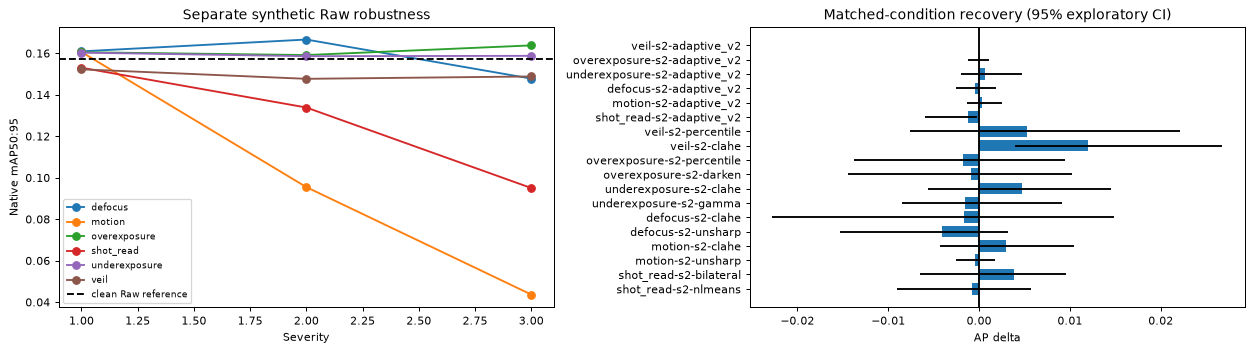

,experiment,family,severity,operator,AP50,AP50_95,class,images,instances,recall
0,clean-s0-skip,clean,0,skip,0.495057,0.273473,car,254,2621,0.439908
1,clean-s0-skip,clean,0,skip,0.265725,0.185070,truck,75,122,0.360656
2,clean-s0-skip,clean,0,skip,0.248542,0.192724,bus,40,48,0.270833
3,clean-s0-skip,clean,0,skip,0.000000,0.000000,train,1,1,0.000000
4,clean-s0-skip,clean,0,skip,0.258061,0.157543,motorcycle,10,16,0.312500
5,clean-s0-skip,clean,0,skip,0.238160,0.133682,bicycle,12,22,0.181818


In [4]:
clean_ap = results[key("clean", 0, "skip")]["overall"]["mAP50_95"]
matrix_rows, class_rows = [], []
for family, severity, operator in conditions:
    name = key(family, severity, operator)
    raw_name = key(family, severity, "skip")
    result, table = results[name], tables[name]
    row = {
        "experiment": name,
        "family": family,
        "severity": severity,
        "operator": operator,
        **result["overall"],
        "images": len(pilot["rows"]),
        "degradation": clean_ap - results[raw_name]["overall"]["mAP50_95"],
        "recovery": result["overall"]["mAP50_95"] - results[raw_name]["overall"]["mAP50_95"],
        "restore_p50_ms": float(table.restore_ms.quantile(0.5)),
        "restore_p95_ms": float(table.restore_ms.quantile(0.95)),
        "corruption_p50_ms": float(table.corruption_ms.quantile(0.5)),
        "corruption_p95_ms": float(table.corruption_ms.quantile(0.95)),
        "image_GiB": sum(Path(p).stat().st_size for p in table.image) / 2**30,
        "model_inference_ms": result["model_speed_ms"]["inference"],
    }
    if operator != "skip":
        before = load_stats(RUN_ROOT / "evaluation" / raw_name / "paired_stats.npz")
        after = load_stats(RUN_ROOT / "evaluation" / name / "paired_stats.npz")
        # Reaggregation is checked against the native full validation before bootstrapping.
        assert abs(native_ap(after, list(after)) - result["overall"]["mAP50_95"]) < 1e-8
        row.update(paired_interval(before, after, pilot, resamples=BOOTSTRAPS, seed=SEED))
    matrix_rows.append(row)
    class_rows.extend(
        {"experiment": name, "family": family, "severity": severity, "operator": operator, **c}
        for c in result["classes"]
    )
matrix = pd.DataFrame(matrix_rows)
classes = pd.DataFrame(class_rows)
matrix.to_csv(REPORT_ROOT / "experimental_matrix.csv", index=False)
classes.to_csv(REPORT_ROOT / "per_class.csv", index=False)
display(
    matrix[
        [
            "family",
            "severity",
            "operator",
            "mAP50_95",
            "degradation",
            "recovery",
            "recovery_ci_low",
            "recovery_ci_high",
            "restore_p95_ms",
        ]
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw = matrix[(matrix.operator == "skip") & (matrix.family != "clean")]
for family, frame in raw.groupby("family"):
    axes[0].plot(frame.severity, frame.mAP50_95, marker="o", label=family)
axes[0].axhline(clean_ap, color="black", linestyle="--", label="clean Raw reference")
axes[0].set(title="Separate synthetic Raw robustness", xlabel="Severity", ylabel="Native mAP50:95")
axes[0].legend(fontsize=7)
screen = matrix[(matrix.operator != "skip") & (matrix.family != "clean")].copy()
axes[1].barh(screen.experiment, screen.recovery)
axes[1].errorbar(
    screen.recovery,
    range(len(screen)),
    xerr=[
        np.maximum(0, screen.recovery - screen.recovery_ci_low),
        np.maximum(0, screen.recovery_ci_high - screen.recovery),
    ],
    fmt="none",
    color="black",
)
axes[1].axvline(0, color="black")
axes[1].set(title="Matched-condition recovery (95% exploratory CI)", xlabel="AP delta")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "detection_recovery.png")
plt.show()
display(classes[classes.experiment == key("clean", 0, "skip")])

## Quality/reference diagnostics and noise/blur detection errors

PSNR uses a true paired clean JPEG95 reference and is a diagnostic only. The legacy
noise proxy is computed after resizing to at most 512 pixels; median residuals can
collapse after quantization/low-texture regions. A candidate full-resolution statistic
uses mean absolute response of a normalized second-difference kernel. Edges and
compression can inflate it: this is **not a validated sensor-noise estimator**.

For diagnostic classification only, set noise thresholds at the clean pilot 95th
percentile (legacy floor 0.035 is also shown) and blur at clean sharpness 5th percentile.
Report in-sample clean false positives, known-corruption sensitivity/false negatives,
and cross-corruption false positives. These thresholds are screening diagnostics,
not a frozen production router; they use no corruption label at inference.
Blur-induced visibility loss, exposure clipping and uniform veil are explicitly
approximate. No claim of real camera-noise or atmospheric-depth calibration is made.

,family,severity,estimator,images,detection_rate,false_positive_rate,false_negative_rate
0,clean,0,legacy_floor,256,0.000000,0.000000,NaN
1,clean,0,legacy_q95,256,0.000000,0.000000,NaN
2,clean,0,highpass_q95,256,0.050781,0.050781,NaN
3,clean,0,blur_q05,256,0.050781,0.050781,NaN
4,defocus,1,legacy_floor,256,0.000000,0.000000,NaN
...,...,...,...,...,...,...,...
71,veil,2,blur_q05,256,0.148438,0.148438,NaN
72,veil,3,legacy_floor,256,0.000000,0.000000,NaN
73,veil,3,legacy_q95,256,0.000000,0.000000,NaN
74,veil,3,highpass_q95,256,0.003906,0.003906,NaN


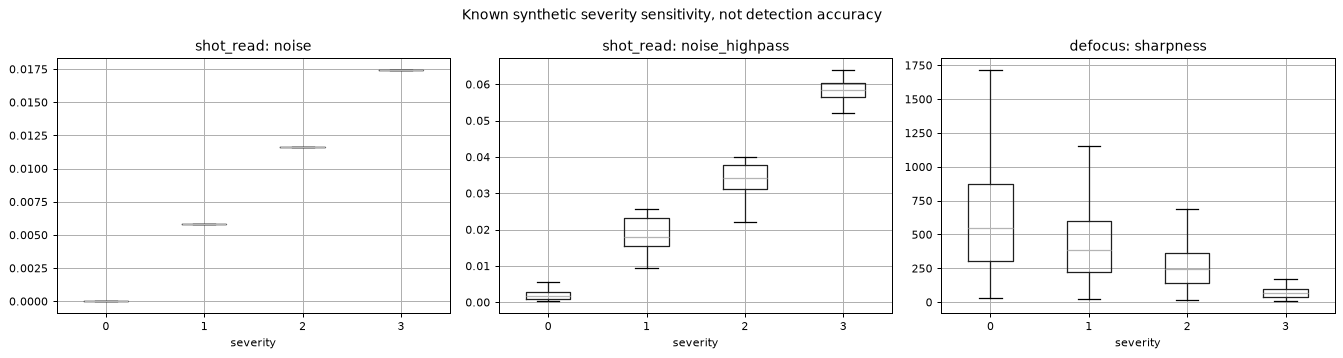

brightness  contrast    sharpness     noise  \
family        severity                                                
clean         0           0.288348  0.192741   634.317091  0.000363   
defocus       1           0.288341  0.191901   438.458776  0.000136   
              2           0.288340  0.190789   263.986110  0.000045   
              3           0.288337  0.187897    71.589937  0.000000   
motion        1           0.288339  0.190442   278.322625  0.000091   
              2           0.288337  0.186701   140.059119  0.000045   
              3           0.288337  0.181650    87.129109  0.000000   
overexposure  1           0.321594  0.209349   765.809425  0.000409   
              2           0.355798  0.222199   884.068526  0.000432   
              3           0.394687  0.232646   995.289393  0.000454   
shot_read     1           0.287972  0.192479   689.917997  0.005928   
              2           0.287736  0.191785   813.552228  0.011560   
              3           0.287514  0.189264  1163.660606  0.018123   
underexposure 1           0.245267  0.163907   460.417603  0.000159   
              2           0.200539  0.134095   308.753776  0.000114   
              3           0.153542  0.102688   181.717804  0.000068   
veil          1           0.349493  0.173484   515.331432  0.000273   
              2           0.441275  0.144667   358.655427  0.000136   
              3           0.533018  0.115720   230.521416  0.000114   

                        noise_highpass  white_fraction  black_fraction  \
family        severity                                                   
clean         0               0.002117        0.010546        0.036847   
defocus       1               0.001133        0.010366        0.036770   
              2               0.000993        0.010118        0.036447   
              3               0.000848        0.009463        0.035507   
motion        1               0.001269        0.010070        0.036336   
              2               0.001041        0.009194        0.034989   
              3               0.000928        0.008031        0.033366   
overexposure  1               0.002375        0.029507        0.034751   
              2               0.002610        0.053188        0.024164   
              3               0.002886        0.080804        0.023608   
shot_read     1               0.018925        0.009532        0.000577   
              2               0.034183        0.004173        0.000047   
              3               0.058374        0.000257        0.000004   
underexposure 1               0.001882        0.000000        0.042641   
              2               0.001608        0.000000        0.056768   
              3               0.001313        0.000000        0.079371   
veil          1               0.001967        0.008164        0.000000   
              2               0.001702        0.000000        0.000000   
              3               0.001440        0.000000        0.000000   

                          psnr_db  
family        severity             
clean         0               NaN  
defocus       1         40.365527  
              2         35.234772  
              3         30.079758  
motion        1         33.553854  
              2         28.715266  
              3         25.842152  
overexposure  1         29.231200  
              2         23.118521  
              3         19.142977  
shot_read     1         34.068595  
              2         28.550472  
              3         23.598653  
underexposure 1         26.733106  
              2         20.567411  
              3         16.848502  
veil          1         23.861225  
              2         15.910958  
              3         11.826374

In [5]:
clean_table = tables[key("clean", 0, "skip")].set_index("id")
quality_rows = []
clean_pixels = {i: read_image(p) for i, p in clean_table.image.items()}
for family, severity, operator in conditions:
    if operator != "skip":
        continue
    for record in tables[key(family, severity, operator)].to_dict("records"):
        image = read_image(record["image"])
        mse = float(
            np.mean((image.astype(np.float32) - clean_pixels[record["id"]].astype(np.float32)) ** 2)
        )
        quality_rows.append(
            {
                "family": family,
                "severity": severity,
                **record,
                "psnr_db": 10 * np.log10(255**2 / mse) if mse > 0 else None,
            }
        )
quality_data = pd.DataFrame(quality_rows)
quality_data.drop(columns="image").to_csv(RUN_ROOT / "quality_per_image.csv", index=False)
thresholds = {
    "legacy_noise_floor": 0.035,
    "legacy_noise_q95": float(clean_table.noise.quantile(0.95)),
    "highpass_q95": float(clean_table.noise_highpass.quantile(0.95)),
    "sharpness_q05": float(clean_table.sharpness.quantile(0.05)),
}
diagnostic_rows = []
for (family, severity), group in quality_data.groupby(["family", "severity"]):
    tests = {
        "legacy_floor": group.noise > thresholds["legacy_noise_floor"],
        "legacy_q95": group.noise > thresholds["legacy_noise_q95"],
        "highpass_q95": group.noise_highpass > thresholds["highpass_q95"],
        "blur_q05": group.sharpness < thresholds["sharpness_q05"],
    }
    for estimator, detected in tests.items():
        target = (
            family in {"motion", "defocus"} if estimator == "blur_q05" else family == "shot_read"
        )
        rate = float(detected.mean())
        diagnostic_rows.append(
            {
                "family": family,
                "severity": severity,
                "estimator": estimator,
                "images": len(group),
                "detection_rate": rate,
                "false_positive_rate": rate if not target else None,
                "false_negative_rate": 1 - rate if target else None,
            }
        )
estimators = pd.DataFrame(diagnostic_rows)
estimators.to_csv(REPORT_ROOT / "estimator_errors.csv", index=False)
write_json(REPORT_ROOT / "diagnostic_thresholds.json", thresholds)
display(estimators)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, family in zip(
    axes,
    ["noise", "noise_highpass", "sharpness"],
    ["shot_read", "shot_read", "defocus"],
    strict=True,
):
    data = quality_data[quality_data.family.isin(["clean", family])]
    data.boxplot(column=metric, by="severity", ax=ax, showfliers=False)
    ax.set_title(f"{family}: {metric}")
fig.suptitle("Known synthetic severity sensitivity, not detection accuracy")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "estimator_sensitivity.png")
plt.show()
display(
    quality_data.groupby(["family", "severity"])[
        [
            "brightness",
            "contrast",
            "sharpness",
            "noise",
            "noise_highpass",
            "white_fraction",
            "black_fraction",
            "psnr_db",
        ]
    ].mean()
)
del clean_pixels
quality_data.groupby(["family", "severity"])[
    [
        "brightness",
        "contrast",
        "noise",
        "noise_highpass",
        "sharpness",
        "white_fraction",
        "black_fraction",
        "psnr_db",
    ]
].mean().add_prefix("mean_").reset_index().to_csv(
    REPORT_ROOT / "quality_diagnostics.csv", index=False
)

## Paired restoration quality and severity visibility checks

These additional diagnostics reuse the exact frozen exports and do not change the
experimental matrix or select new images for evaluation. Pooled PSNR is computed from
mean squared error against each true clean JPEG95 reference; identical references
are counted explicitly rather than replacing infinite PSNR with a finite value.
A positive quality recovery can coexist with negative AP recovery.

The severity grid uses the median-brightness pilot image, selected independently of
AP. It shows all families and levels so visible information loss and the limitations
of the corruption approximations can be inspected offline. Memory values below are
buffer/workspace estimates, not measured process/GPU peak memory.

The archived v2 sample is also inspected for priority masking: potential sharpening
support is counted before the higher-priority Gamma route, without modifying v2.

Clean means no added corruption, not a physically pristine/noise-free sensor
reference. False positives refer to controlled corruption labels; natural noise
and texture remain unresolved. Only one strength per operator is screened.

,family,severity,operator,pooled_psnr_db,mse_recovery
0,clean,0,skip,NaN,0.000000
1,shot_read,1,skip,33.577731,0.000000
2,shot_read,2,skip,28.353256,0.000000
3,shot_read,3,skip,23.557024,0.000000
4,motion,1,skip,31.751946,0.000000
5,motion,2,skip,27.424342,0.000000
6,motion,3,skip,24.796327,0.000000
7,defocus,1,skip,38.579409,0.000000
8,defocus,2,skip,33.579126,0.000000
9,defocus,3,skip,28.777823,0.000000


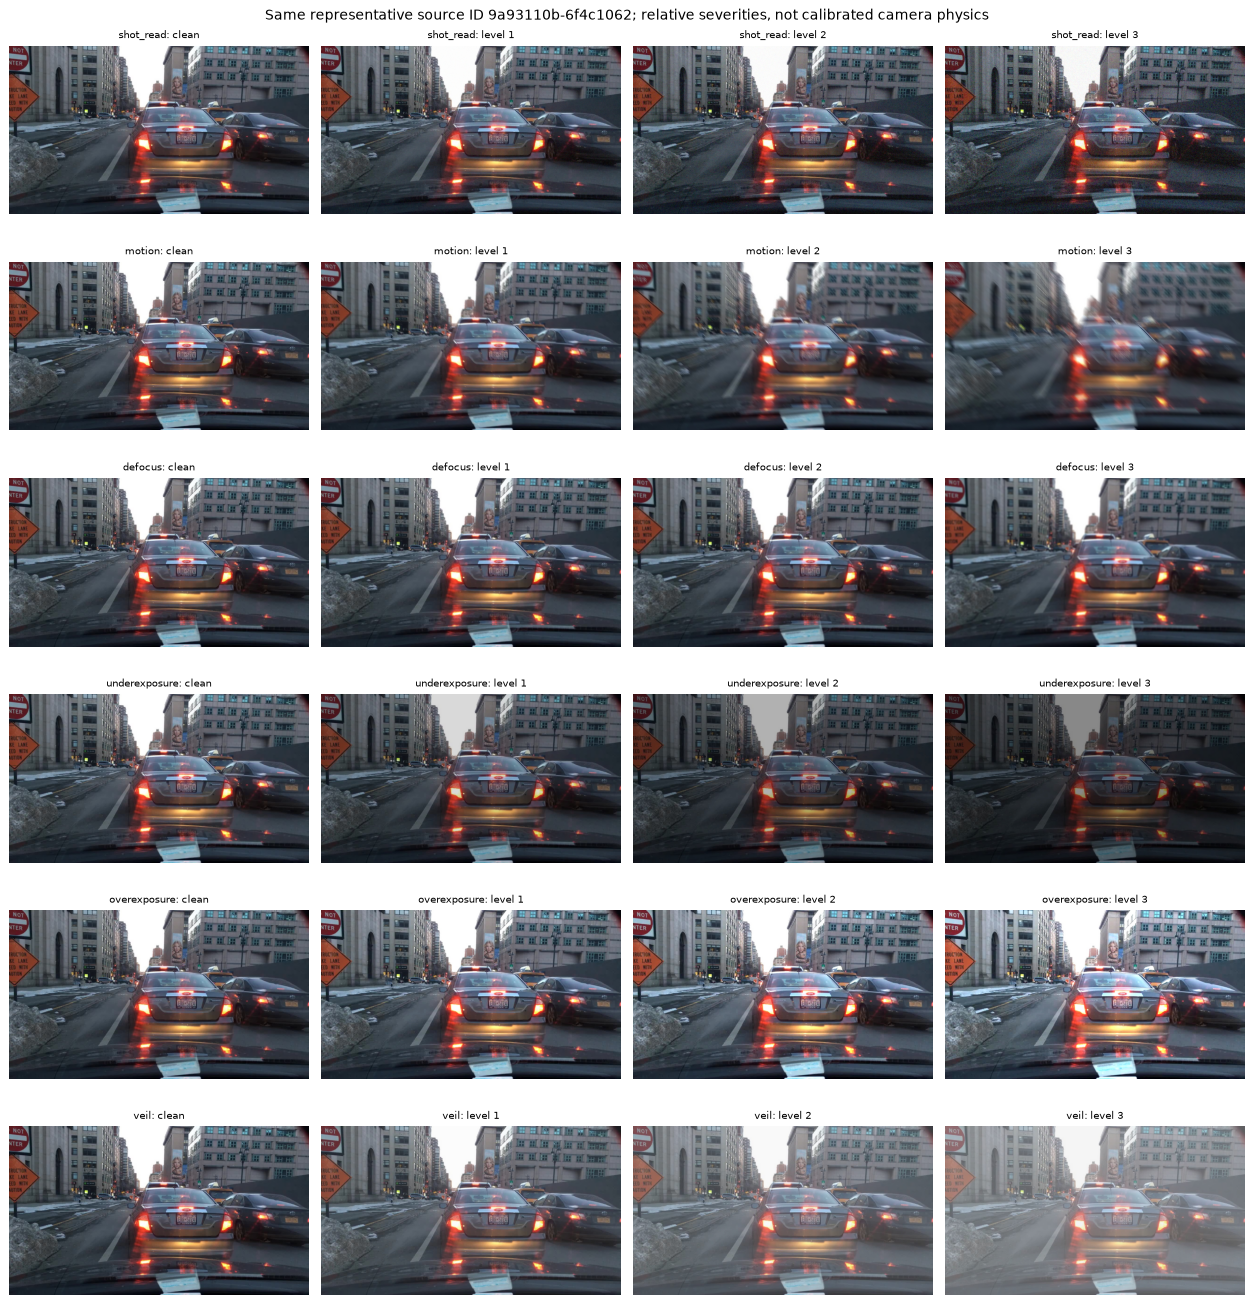

{'v2_policy_id': '1ac3fb9bb94b132f70d3e168b5ef15a54b616444e535b9a3bb265682a6fce0ef',
 'potential_sharpen_before_priority': 8,
 'masked_by_gamma': 8,
 'initial_sharpness_upper': 80.0,
 'initial_noise_floor': 0.035,
 'note': 'Diagnostic only; frozen v2 is unchanged'}

{'one_uint8_BGR_frame_MiB': 2.63671875,
 'clean_reference_cache_MiB': 675.0,
 'generator_workspace_allowance_MiB': 256,
 'native_FP32_input_batch_MiB': 150.0,
 'note': 'Estimates, excluding Python/protocol/Torch overhead, native activations and backend workspaces'}

In [6]:
quality_summary = []
reference = tables[key("clean", 0, "skip")].set_index("id")
reference_pixels = {i: read_image(p) for i, p in reference.image.items()}
for family, severity, operator in conditions:
    table = tables[key(family, severity, operator)]
    errors = []
    for record in table.to_dict("records"):
        a = read_image(record["image"]).astype(np.float32)
        b = reference_pixels[record["id"]].astype(np.float32)
        errors.append(float(np.mean((a - b) ** 2)))
    mse = float(np.mean(errors))
    quality_summary.append(
        {
            "family": family,
            "severity": severity,
            "operator": operator,
            "mean_mse": mse,
            "pooled_psnr_db": float(10 * np.log10(255**2 / mse)) if mse else None,
            "identical_reference_images": sum(e == 0 for e in errors),
            **{
                f"mean_{k}": float(table[k].mean())
                for k in [
                    "brightness",
                    "contrast",
                    "noise",
                    "noise_highpass",
                    "sharpness",
                    "white_fraction",
                    "black_fraction",
                ]
            },
        }
    )
restoration_quality = pd.DataFrame(quality_summary)
raw_quality = restoration_quality[restoration_quality.operator == "skip"][
    ["family", "severity", "mean_mse"]
]
raw_quality = raw_quality.rename(columns={"mean_mse": "corrupted_raw_mse"})
restoration_quality = restoration_quality.merge(
    raw_quality, on=["family", "severity"], validate="many_to_one"
)
restoration_quality["mse_recovery"] = (
    restoration_quality.corrupted_raw_mse - restoration_quality.mean_mse
)
restoration_quality.to_csv(REPORT_ROOT / "paired_restoration_quality.csv", index=False)
display(restoration_quality[["family", "severity", "operator", "pooled_psnr_db", "mse_recovery"]])
representative = reference.assign(
    distance=(reference.brightness - reference.brightness.median()).abs()
)
sample_id = representative.sort_values(["distance", "id"]).iloc[0].name
fig, axes = plt.subplots(len(CORRUPTIONS), 4, figsize=(14, 15))
for i, family in enumerate(CORRUPTIONS):
    for j, severity in enumerate([0, 1, 2, 3]):
        name = key("clean", 0, "skip") if severity == 0 else key(family, severity, "skip")
        image = read_image(tables[name].set_index("id").loc[sample_id, "image"])
        axes[i, j].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(
            f"{family}: {'clean' if severity == 0 else 'level ' + str(severity)}", fontsize=8
        )
        axes[i, j].axis("off")
fig.suptitle(
    f"Same representative source ID {sample_id}; relative severities, not calibrated camera physics"
)
fig.tight_layout()
fig.savefig(RUN_ROOT / "severity_grid.png")
plt.show()
del reference_pixels
legacy = pd.DataFrame(v2["measurements"])
brightness_cut = float(np.clip(legacy.brightness.quantile(0.2), 0.12, 0.28))
noise_cut = float(np.clip(legacy.noise.quantile(0.9), 0.035, 0.12))
sharp_cut = float(np.clip(legacy.sharpness.quantile(0.2), 10, 80))
potential = (legacy.sharpness >= 10) & (legacy.sharpness < sharp_cut) & (legacy.noise <= noise_cut)
masking = {
    "v2_policy_id": v2["policy_id"],
    "potential_sharpen_before_priority": int(potential.sum()),
    "masked_by_gamma": int((potential & (legacy.brightness < brightness_cut)).sum()),
    "initial_sharpness_upper": sharp_cut,
    "initial_noise_floor": noise_cut,
    "note": "Diagnostic only; frozen v2 is unchanged",
}
write_json(REPORT_ROOT / "v2_priority_masking.json", masking)
display(masking)
frame_bytes = max(r["width"] * r["height"] * 3 for r in pilot["rows"])
memory_budget = {
    "one_uint8_BGR_frame_MiB": frame_bytes / 2**20,
    "clean_reference_cache_MiB": sum(r["width"] * r["height"] * 3 for r in pilot["rows"]) / 2**20,
    "generator_workspace_allowance_MiB": 256,
    "native_FP32_input_batch_MiB": SETTINGS["batch"] * 3 * SETTINGS["imgsz"] ** 2 * 4 / 2**20,
    "note": (
        "Estimates, excluding Python/protocol/Torch overhead, "
        "native activations and backend workspaces"
    ),
}
write_json(REPORT_ROOT / "memory_budget.json", memory_budget)
display(memory_budget)

## Supported natural-condition and size-presence image slices

These are native AP reaggregations on the **same source-image slices** for every
condition, without further inference or tuning. Require at least 30 images per slice;
show sample support and class presence. Size slices mean **images containing at least
one small/medium/large object**, with all their original boxes retained. They overlap
and are not COCO object-area AP_small/AP_medium/AP_large. Rare-class and subgroup
results remain unstable, and synthetic copies do not increase support.

In [7]:
slices = {}
for axis in ["weather", "timeofday", "scene"]:
    for value in sorted({r["attributes"][axis] for r in pilot["rows"]}):
        ids = [r["id"] for r in pilot["rows"] if r["attributes"][axis] == value]
        if len(ids) >= 30:
            slices[f"{axis}:{value}"] = ids
for size, low, high in [
    ("small", 0, 32**2),
    ("medium", 32**2, 96**2),
    ("large", 96**2, float("inf")),
]:
    ids = [
        r["id"]
        for r in pilot["rows"]
        if any(low <= (b[3] - b[1]) * (b[4] - b[2]) < high for b in r["boxes"])
    ]
    if len(ids) >= 30:
        slices[f"image_has_{size}"] = ids
slice_rows = []
for family, severity, operator in conditions:
    name = key(family, severity, operator)
    stats = load_stats(RUN_ROOT / "evaluation" / name / "paired_stats.npz")
    for name_slice, ids in slices.items():
        slice_rows.append(
            {
                "experiment": name,
                "slice": name_slice,
                "images": len(ids),
                "mAP50_95": native_ap(stats, ids),
            }
        )
slice_results = pd.DataFrame(slice_rows)
slice_results.to_csv(REPORT_ROOT / "supported_image_slices.csv", index=False)
display(
    slice_results[
        slice_results.experiment.isin(
            [key("clean", 0, "skip"), key("shot_read", 2, "skip"), key("shot_read", 2, "bilateral")]
        )
    ]
)
slice_support_rows = []
for name_slice, ids in slices.items():
    subset_summary = summarize([r for r in pilot["rows"] if r["id"] in set(ids)])
    for cls in CLASSES:
        support = subset_summary.get(f"presence:{cls}", 0)
        slice_support_rows.append(
            {
                "slice": name_slice,
                "class": cls,
                "slice_images": len(ids),
                "class_images": support,
                "instances": subset_summary.get(f"instances:{cls}", 0),
                "rare_support": support < 5,
            }
        )
slice_support = pd.DataFrame(slice_support_rows)
slice_support.to_csv(REPORT_ROOT / "image_slice_support.csv", index=False)
display(slice_support[slice_support.rare_support])

,experiment,slice,images,mAP50_95
0,clean-s0-skip,weather:clear,131,0.128082
1,clean-s0-skip,weather:overcast,33,0.261531
2,clean-s0-skip,weather:undefined,32,0.265983
3,clean-s0-skip,timeofday:daytime,137,0.164611
4,clean-s0-skip,timeofday:night,101,0.128994
5,clean-s0-skip,scene:city street,164,0.149111
6,clean-s0-skip,scene:highway,54,0.236451
7,clean-s0-skip,scene:residential,35,0.438776
8,clean-s0-skip,image_has_small,214,0.159187
9,clean-s0-skip,image_has_medium,239,0.158064


,slice,class,slice_images,class_images,instances,rare_support
3,weather:clear,train,131,1,1,True
9,weather:overcast,train,33,0,0,True
10,weather:overcast,motorcycle,33,1,2,True
11,weather:overcast,bicycle,33,4,7,True
15,weather:undefined,train,32,0,0,True
16,weather:undefined,motorcycle,32,1,1,True
17,weather:undefined,bicycle,32,1,5,True
21,timeofday:daytime,train,137,1,1,True
22,timeofday:daytime,motorcycle,137,4,5,True
27,timeofday:night,train,101,0,0,True


## Representative before/after and detector failure candidates

Visualizations below contain **real frozen YOLO predictions**, filtered by the same
semantic six-class mapping. Display confidence is 0.25 for readability; AP above uses
0.001 and native matching. Ground truth boxes are green; predictions are orange.
The worst recovery pair is selected for diagnosis after screening, not for changing
the cohort, severity or recipe. Severe examples expose visibility/annotation ambiguity.
Selected embeds are intentional; full image roots and predictions remain gitignored.

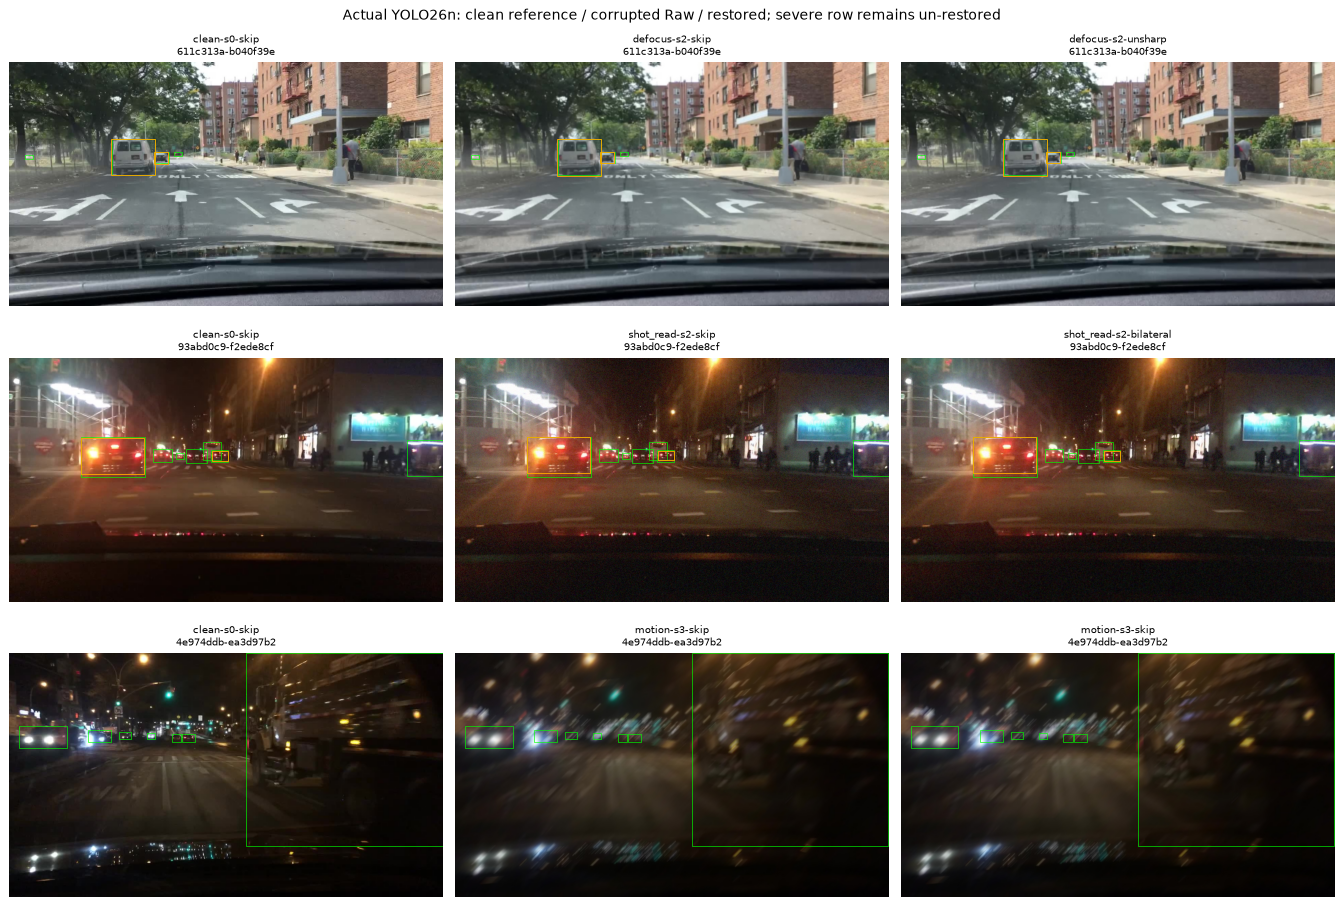

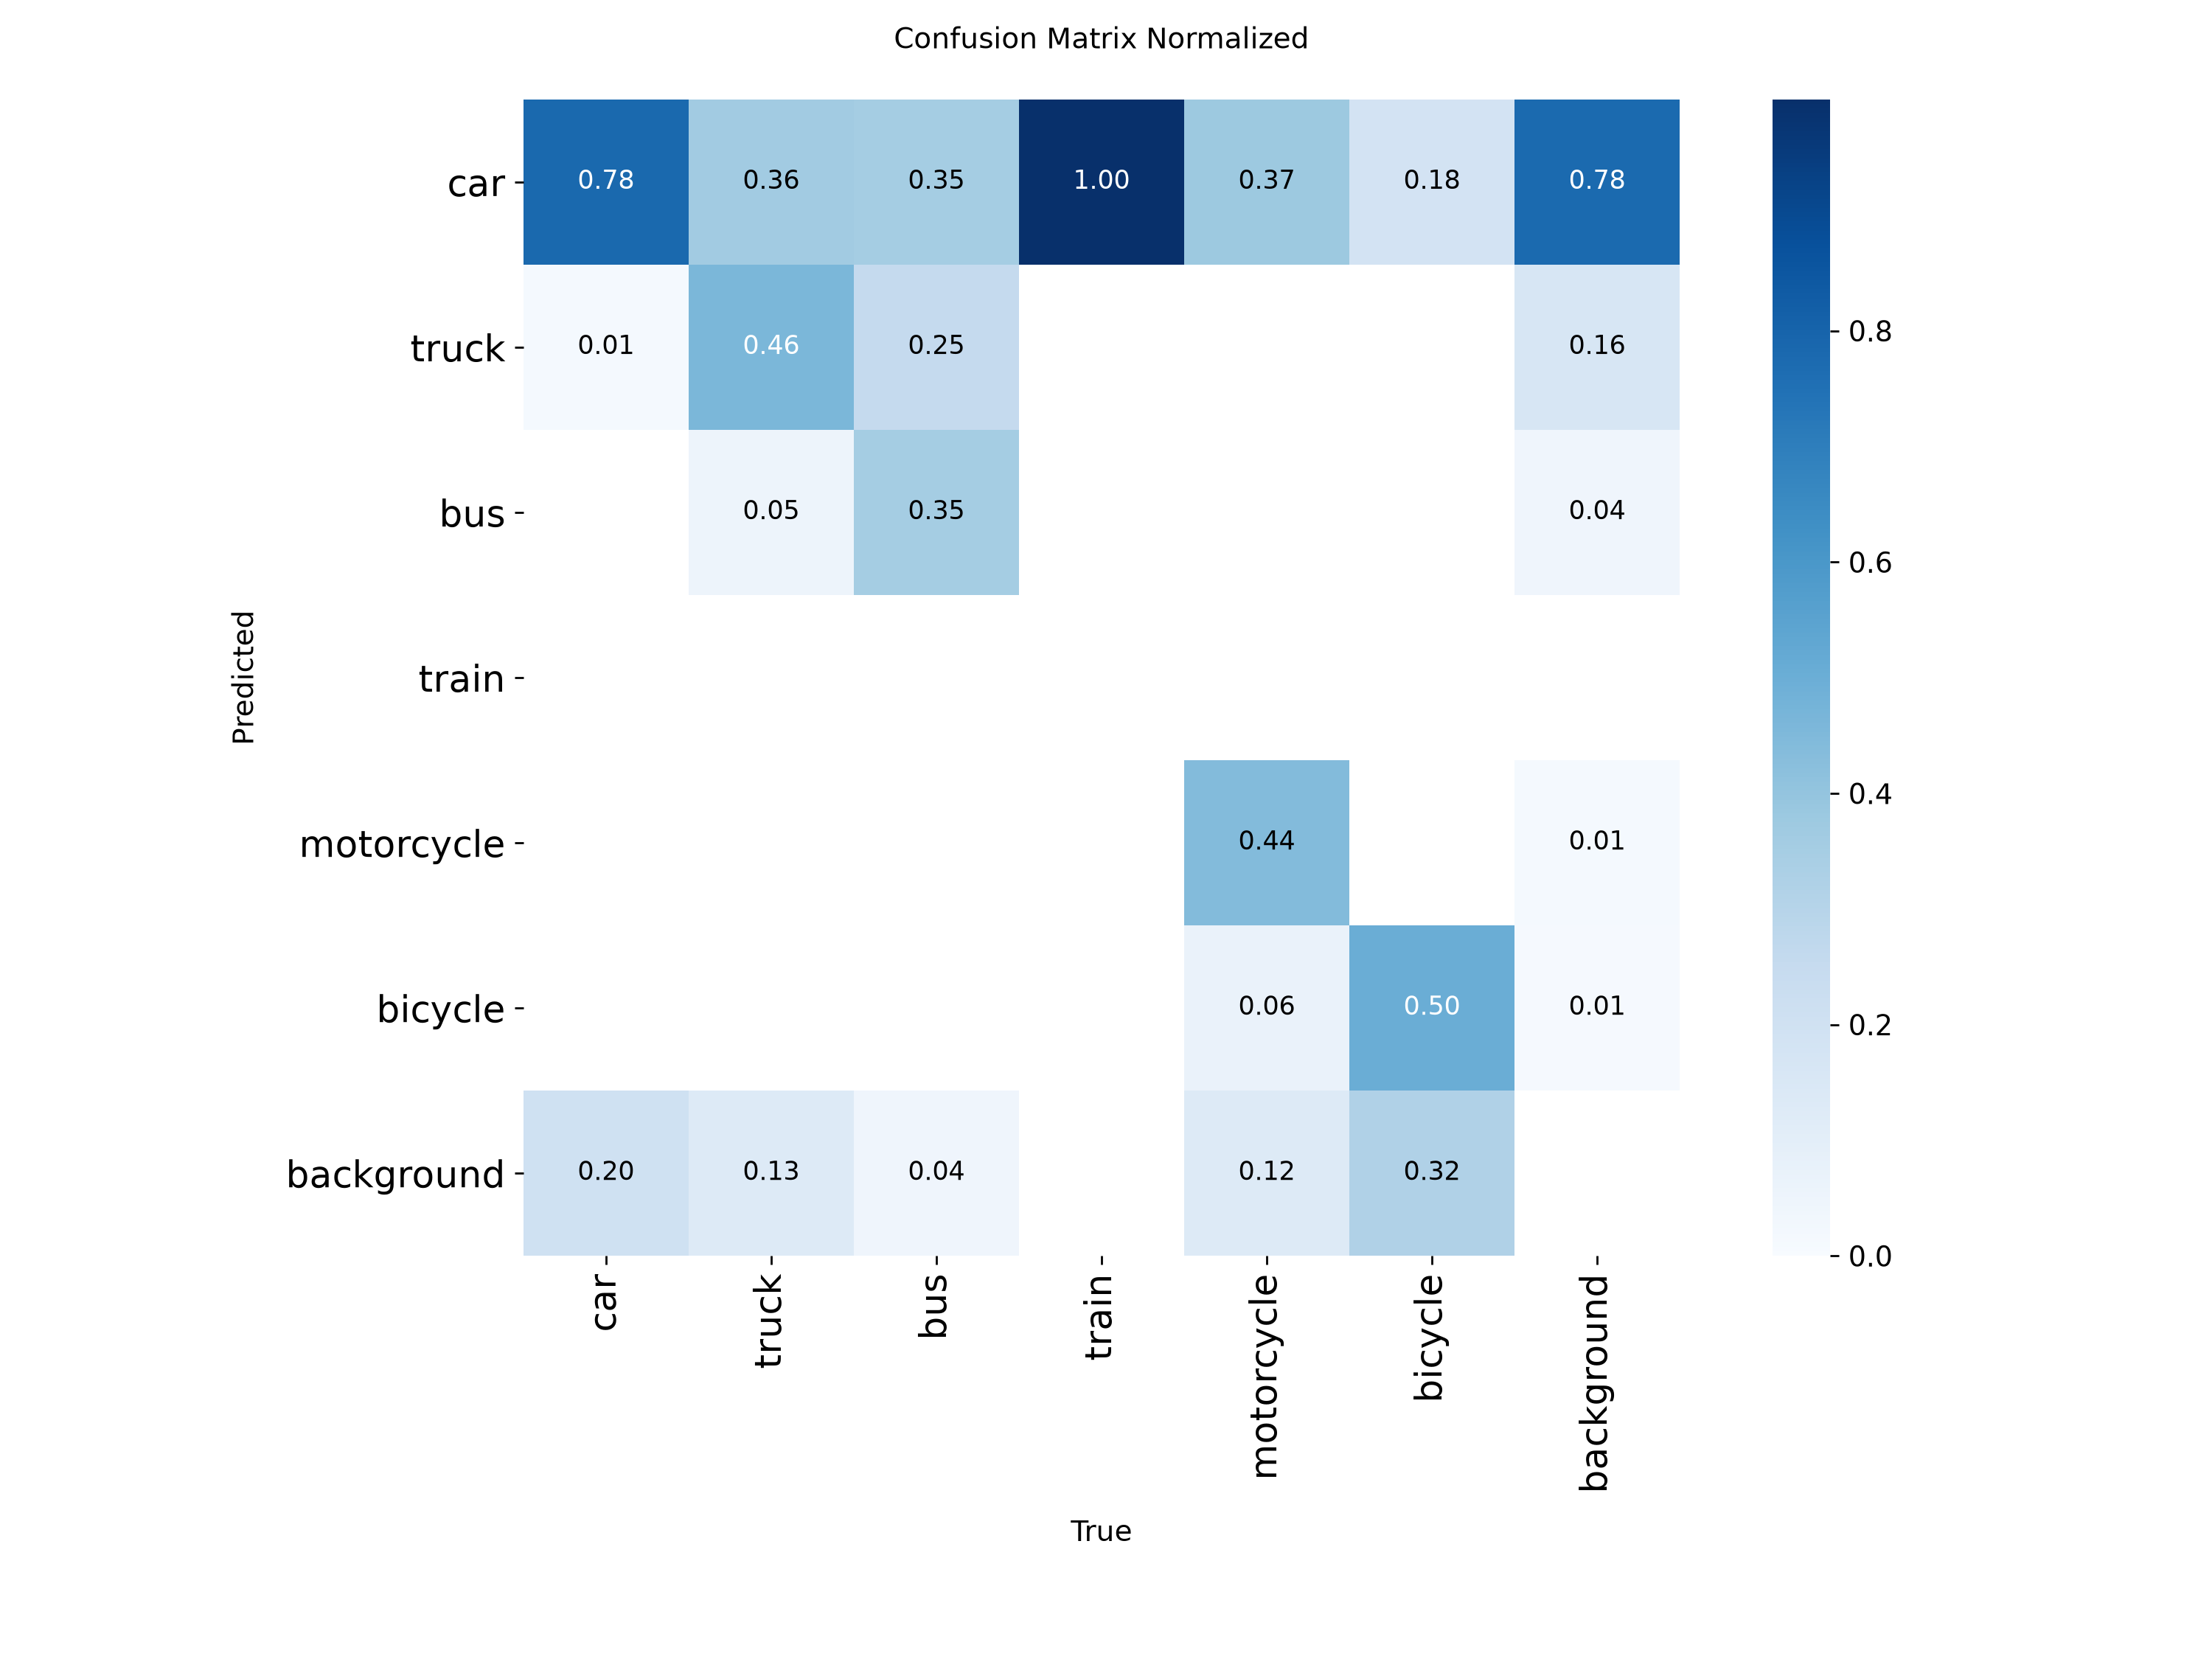

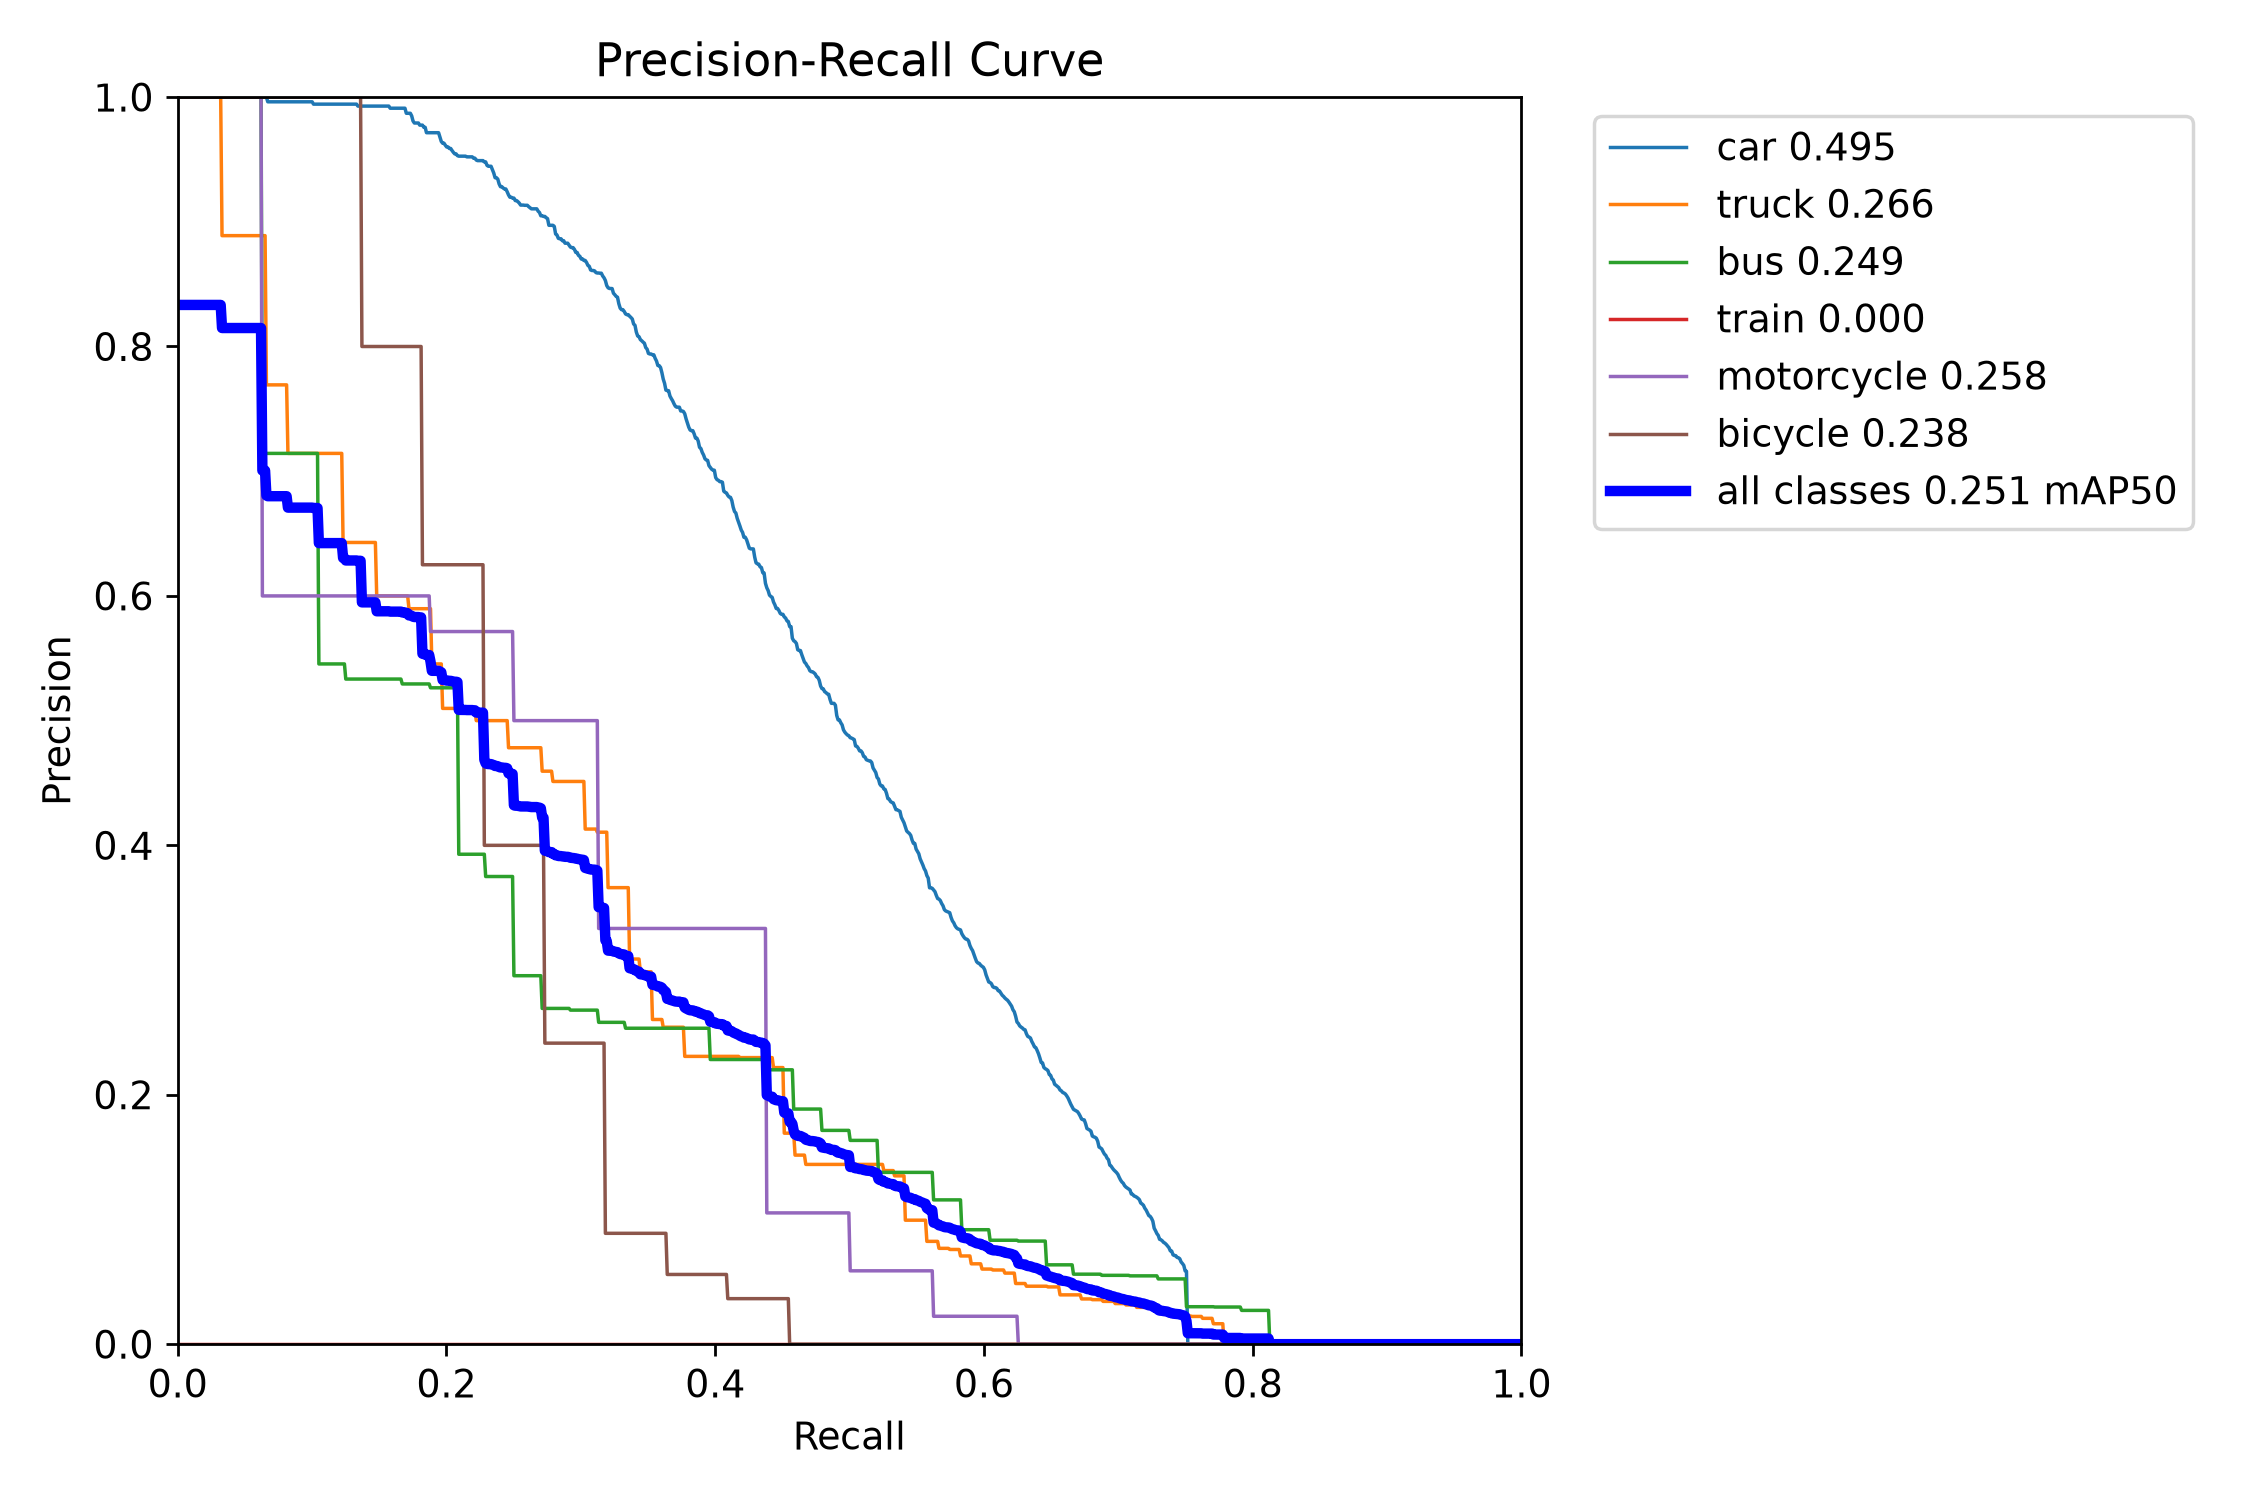

In [8]:
adverse = screen[screen.operator != "adaptive_v2"].sort_values(["recovery", "experiment"]).iloc[0]
family, severity, operator = adverse.family, int(adverse.severity), adverse.operator
before = load_stats(RUN_ROOT / "evaluation" / key(family, severity, "skip") / "paired_stats.npz")
after = load_stats(RUN_ROOT / "evaluation" / key(family, severity, operator) / "paired_stats.npz")
ranked = []
for r in pilot["rows"]:
    a, b = native_ap(before, [r["id"]]), native_ap(after, [r["id"]])
    if a is not None and b is not None:
        ranked.append((b - a, r["id"]))
ranked.sort()
example_specs = [
    (family, severity, operator, ranked[0][1]),
    ("shot_read", 2, "bilateral", ranked[len(ranked) // 2][1]),
    ("motion", 3, "skip", ranked[-1][1]),
]
model = YOLO(str(CHECKPOINT))
verify_coco_names(model.names)
rows_by_id = {r["id"]: r for r in pilot["rows"]}
fig, axes = plt.subplots(len(example_specs), 3, figsize=(15, 3.5 * len(example_specs)))
for i, (f, s, op, sample_id) in enumerate(example_specs):
    names = [key("clean", 0, "skip"), key(f, s, "skip"), key(f, s, op)]
    for j, name in enumerate(names):
        record = tables[name].set_index("id").loc[sample_id]
        image = read_image(record.image)
        axes[i, j].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        pred = model.predict(
            str(record.image), imgsz=640, conf=0.25, iou=0.7, nms=False, device=0, verbose=False
        )[0]
        for box in rows_by_id[sample_id]["boxes"]:
            _, x1, y1, x2, y2 = box
            axes[i, j].add_patch(
                Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", linewidth=0.5)
            )
        for xyxy, cls, _conf in zip(
            pred.boxes.xyxy.cpu().numpy(),
            pred.boxes.cls.cpu().numpy(),
            pred.boxes.conf.cpu().numpy(),
            strict=True,
        ):
            if int(cls) not in COCO_TO_VEHICLE:
                continue
            x1, y1, x2, y2 = xyxy
            axes[i, j].add_patch(
                Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="orange", linewidth=0.7)
            )
        axes[i, j].set_title(f"{name}\n{sample_id}", fontsize=8)
        axes[i, j].axis("off")
fig.suptitle(
    "Actual YOLO26n: clean reference / corrupted Raw / restored; severe row remains un-restored"
)
fig.tight_layout()
fig.savefig(RUN_ROOT / "detector_examples.png")
plt.show()
assert file_hash(CHECKPOINT) == PRETRAINED_SHA256
for pattern in ["confusion_matrix_normalized.png", "*PR_curve.png"]:
    display(
        Image(
            filename=str(
                sorted((RUN_ROOT / "evaluation" / key("clean", 0, "skip")).glob(pattern))[0]
            ),
            width=700,
        )
    )

## Decision and frozen specification for the later final benchmark

Apply the predeclared AP/CI/clean-safety/cost shortlist gates, and disclose failures.
This pilot reuses calibration images to explore candidates and estimators; it is not
independent policy confirmation. Therefore **do not deploy/freeze Adaptive v3 here**.
Retain the exact frozen v2 baseline for downstream #7 until an independently confirmed
pixel-only router meets the declared requirements. A future version may replace or
remove any operator; four historical routes are not mandatory winners.

The #8 specification below reserves naturally distributed clean final test plus
separately labeled synthetic conditions/severities, same source IDs and GT, checkpoint
and metric settings. It records no final-test pixel hashes/results: final release
must first complete the outstanding holdout content/geometry/leakage checks.
Synthetic AP must never be blended into a single real-world accuracy claim.

In [9]:
shortlist_rows = []
for row in screen[screen.operator != "adaptive_v2"].to_dict("records"):
    clean_row = matrix[(matrix.family == "clean") & (matrix.operator == row["operator"])].iloc[0]
    clean_loss = clean_ap - float(clean_row.mAP50_95)
    passes = (
        row["recovery"] >= 0.005
        and row["recovery_ci_low"] > 0
        and clean_loss <= 0.01
        and row["restore_p95_ms"] <= 25
    )
    shortlist_rows.append(
        {
            "family": row["family"],
            "operator": row["operator"],
            "recovery": row["recovery"],
            "ci_low": row["recovery_ci_low"],
            "clean_loss": clean_loss,
            "restore_p95_ms": row["restore_p95_ms"],
            "passes_exploratory_gates": bool(passes),
        }
    )
shortlist = pd.DataFrame(shortlist_rows)
shortlist.to_csv(REPORT_ROOT / "shortlist.csv", index=False)
display(shortlist)
decision = {
    "version": "issue11-v3-decision-v1",
    "study_id": config["study_id"],
    "status": "v3_not_deployed",
    "retained_policy_id": v2["policy_id"],
    "reason": "No independent calibration-group confirmation of a pixel-only router.",
    "shortlist": shortlist[shortlist.passes_exploratory_gates].to_dict("records"),
    "requirements": [
        "Independent groups from calibration only",
        "Predeclared pixel-only router",
        "Paired native AP confirmation and clean safety",
        "Supported estimator false positives/negatives",
        "New version/root; no final-test selection",
    ],
}
decision["decision_id"] = digest(decision)
freeze(REPORT_ROOT / "v3_decision.json", decision)
spec = {
    "version": "issue11-final-stress-spec-v1",
    "protocol_id": protocol["manifest_id"],
    "role": "final_test",
    "reserved_images": len(protocol["splits"]["final_test"]),
    "status": "specification_only_not_executed",
    "source_id_parity": "all conditions use identical final source IDs/groups/GT",
    "natural_clean": "Report separately with natural prevalence; no blending with synthetic AP",
    "synthetic": CORRUPTIONS,
    "seed": SEED,
    "encoding": {"format": "jpg", "quality": 95},
    "models": [
        "frozen pretrained YOLO26n",
        "future Raw-trained model",
        "future Adaptive-trained model",
    ],
    "inputs": ["Raw under same condition", "frozen Adaptive under same condition"],
    "current_policy_id": v2["policy_id"],
    "v3_decision_id": decision["decision_id"],
    "settings": SETTINGS,
    "primary_metric": "native mAP50:95",
    "paired_group_uncertainty": True,
    "release_gate": [
        "model/policy/protocol freeze",
        "final pixel/geometry/content leakage checks",
        "no subsequent retuning",
    ],
}
spec["spec_id"] = digest(spec)
freeze(REPORT_ROOT / "final_robustness_spec.json", spec)
summary = {
    "study_id": config["study_id"],
    "pilot_id": pilot["pilot_id"],
    "checkpoint_sha256": PRETRAINED_SHA256,
    "datasets": len(conditions),
    "images_per_dataset": len(pilot["rows"]),
    "clean_native": results[key("clean", 0, "skip")],
    "policy_decision": decision,
    "final_spec_id": spec["spec_id"],
    "matrix_sha256": file_hash(REPORT_ROOT / "experimental_matrix.csv"),
    "storage_GiB": float(matrix.image_GiB.sum()),
    "budget_GiB": float(budget_gib),
    "environment": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "torch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0),
        "opencv_threads": cv2.getNumThreads(),
    },
    "final_test_pixels_accessed": False,
    "development_pixels_accessed": False,
    "training_run": False,
    "limits": [
        "Small exploratory pilot; absent/rare classes unsupported",
        "100 bootstrap draws; no multiplicity correction",
        "Synthetic approximations are not camera/atmosphere realism",
        "No independently confirmed v3 router",
        "Overlapping size-presence image slices are not COCO area AP",
    ],
}
summary["experiment_identities"] = {
    name: {
        "export_identity_sha256": file_hash(RUN_ROOT / "datasets" / name / "export.json"),
        "files_identity": read_json(RUN_ROOT / "datasets" / name / "verified.json")[
            "files_identity"
        ],
        "native_result_sha256": file_hash(RUN_ROOT / "evaluation" / name / "native_result.json"),
        "statistics_sha256": file_hash(RUN_ROOT / "evaluation" / name / "paired_stats.npz"),
    }
    for name in results
}
summary["supplemental_artifacts"] = {
    name: file_hash(REPORT_ROOT / name)
    for name in [
        "paired_restoration_quality.csv",
        "v2_priority_masking.json",
        "memory_budget.json",
        "image_slice_support.csv",
    ]
}
write_json(REPORT_ROOT / "summary.json", summary)
# Verify cache reuse without allowing another model invocation.
from unittest.mock import patch

with patch("vehicle_detection.stress_eval.YOLO", side_effect=RuntimeError("cache must not infer")):
    cached = evaluate_calibration(
        protocol,
        pilot,
        RUN_ROOT / "datasets" / key("clean", 0, "skip"),
        CHECKPOINT,
        RUN_ROOT / "evaluation" / key("clean", 0, "skip"),
    )
assert cached == results[key("clean", 0, "skip")]
for path, expected in read_json(RUN_ROOT / "frozen_prior_hashes.json").items():
    assert file_hash(ROOT / path) == expected, path
print("PASS: frozen roles, real native metrics, cache reuse, unchanged v1/v2 and checkpoint")
print("V3 is not deployed; final-test specification only, no final-test pixels or training.")

,family,operator,recovery,ci_low,clean_loss,restore_p95_ms,passes_exploratory_gates
0,shot_read,nlmeans,-0.000829,-0.009057,-0.009201,777.216087,False
1,shot_read,bilateral,0.003791,-0.006486,-0.004800,6.864732,False
2,motion,unsharp,-0.000498,-0.002489,-0.001410,2.678012,False
3,motion,clahe,0.003003,-0.004315,-0.003840,8.748091,False
4,defocus,unsharp,-0.004082,-0.015341,-0.001410,2.237546,False
5,defocus,clahe,-0.001636,-0.022746,-0.003840,8.794869,False
6,underexposure,gamma,-0.001557,-0.008484,0.002563,0.760132,False
7,underexposure,clahe,0.004687,-0.005632,-0.003840,10.049760,False
8,overexposure,darken,-0.000865,-0.014415,0.000042,0.855119,False
9,overexposure,percentile,-0.001804,-0.013821,-0.000095,10.989791,False


PASS: frozen roles, real native metrics, cache reuse, unchanged v1/v2 and checkpoint
V3 is not deployed; final-test specification only, no final-test pixels or training.
